In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

In [ ]:
# Study area coordinates
latitude = 35.851
longitude = 71.786

# Historical climate data API
url = "https://archive-api.open-meteo.com/v1/archive"

# Request parameters
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "2000-01-01",
    "end_date": "2025-12-31",
    "daily": "temperature_2m_mean,precipitation_sum",
    "timezone": "Asia/Karachi"
}

# Download data
response = requests.get(url, params=params)

# Check response
print("Status Code:", response.status_code)

# Convert response into JSON
data = response.json()

print("Climate data downloaded successfully!")

Status Code: 200
Climate data downloaded successfully!


In [ ]:
# Convert downloaded data into a DataFrame
df = pd.DataFrame(data["daily"])

# Rename columns
df = df.rename(columns={
    "time": "Date",
    "temperature_2m_mean": "Temperature",
    "precipitation_sum": "Precipitation"
})

# Convert date column
df["Date"] = pd.to_datetime(df["Date"])

# Display first 10 records
df.head(10)

,Date,Temperature,Precipitation
0,2000-01-01,-1.8,0.0
1,2000-01-02,-1.8,0.0
2,2000-01-03,-1.8,0.0
3,2000-01-04,-2.2,0.0
4,2000-01-05,-2.5,0.0
5,2000-01-06,0.3,0.0
6,2000-01-07,1.7,0.0
7,2000-01-08,1.7,11.3
8,2000-01-09,1.1,16.7
9,2000-01-10,-1.5,1.3


In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Number of records
print("\nTotal Records:", len(df))

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (9497, 3)

Total Records: 9497

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9497 entries, 0 to 9496
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9497 non-null   datetime64[ns]
 1   Temperature    9497 non-null   float64       
 2   Precipitation  9497 non-null   float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 222.7 KB

Missing Values:
Date             0
Temperature      0
Precipitation    0
dtype: int64

Statistical Summary:


,Date,Temperature,Precipitation
count,9497,9497.000000,9497.000000
mean,2012-12-31 00:00:00,11.153069,2.586322
min,2000-01-01 00:00:00,-15.900000,0.000000
25%,2006-07-02 00:00:00,2.100000,0.000000
50%,2012-12-31 00:00:00,10.900000,0.000000
75%,2019-07-02 00:00:00,21.600000,1.800000
max,2025-12-31 00:00:00,31.600000,80.300000
std,NaN,10.737615,6.208523


In [ ]:
# Extract year from Date
df["Year"] = df["Date"].dt.year

# Display first records
df[["Date", "Year", "Temperature", "Precipitation"]].head()

,Date,Year,Temperature,Precipitation
0,2000-01-01,2000,-1.8,0.0
1,2000-01-02,2000,-1.8,0.0
2,2000-01-03,2000,-1.8,0.0
3,2000-01-04,2000,-2.2,0.0
4,2000-01-05,2000,-2.5,0.0


In [ ]:
# Calculate annual climate statistics

annual = df.groupby("Year").agg(
    Mean_Temperature=("Temperature", "mean"),
    Total_Precipitation=("Precipitation", "sum")
).reset_index()

# Display annual results
annual

,Year,Mean_Temperature,Total_Precipitation
0,2000,9.262022,857.9
1,2001,9.280548,887.0
2,2002,9.577260,973.1
3,2003,8.708493,1217.6
4,2004,8.696448,1129.1
5,2005,8.212877,1125.3
6,2006,10.187945,1194.6
7,2007,10.308493,1040.0
8,2008,9.847541,1022.3
9,2009,9.020274,1322.2


In [ ]:
# Warmest year
warmest = annual.loc[
    annual["Mean_Temperature"].idxmax()
]

# Coldest year
coldest = annual.loc[
    annual["Mean_Temperature"].idxmin()
]

print("Warmest Year:")
print(warmest)

print("\nColdest Year:")
print(coldest)

Warmest Year:
Year                   2023.000000
Mean_Temperature         15.363014
Total_Precipitation     419.600000
Name: 23, dtype: float64

Coldest Year:
Year                   2012.000000
Mean_Temperature          8.204918
Total_Precipitation    1127.100000
Name: 12, dtype: float64


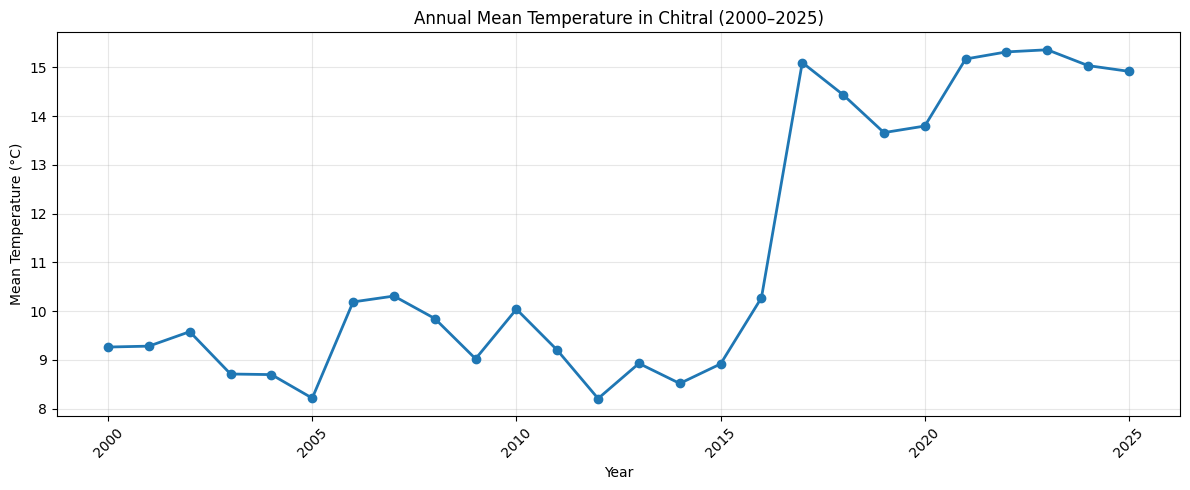

In [ ]:
# Plot annual temperature trend

plt.figure(figsize=(12, 5))

plt.plot(
    annual["Year"],
    annual["Mean_Temperature"],
    marker="o",
    linewidth=2
)

plt.title("Annual Mean Temperature in Chitral (2000–2025)")
plt.xlabel("Year")
plt.ylabel("Mean Temperature (°C)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()